In [ ]:
import tensorflow as tf
import tensorflow.keras as keras
import tensorflow.keras.layers as layers
import numpy as np
import datetime
import matplotlib.pyplot as plt

In [ ]:
xTrain = np.load('./tmp/xTrainFinal.npy')
yTrain = np.load('./tmp/yTrainFinal.npy')
xTest = np.load('./tmp/xTestFinal.npy')
yTest = np.load('./tmp/yTestFinal.npy')

### 使用 tf-keras 定义 CNN 模型。
### 在使用该方法定义模型时是只需要调用对应 API 填入模型各层的参数即可，
### keras 会自动生成训练模型层。该模型的核心为 3 层卷积池化组合，1 层展平和 2 层全连接

In [ ]:
model = keras.Sequential()
model.add(layers.Convolution2D(16, (3, 3), padding='same',
                               input_shape=xTrain.shape[1:], activation='relu'))
model.add(layers.MaxPooling2D(pool_size=(2, 2)))
model.add(layers.Convolution2D(32, (3, 3), padding='same', activation='relu'))
model.add(layers.MaxPooling2D(pool_size=(2, 2)))
model.add(layers.Convolution2D(64, (3, 3), padding='same', activation='relu'))
model.add(layers.MaxPooling2D(pool_size=(2, 2)))
model.add(layers.Flatten())
model.add(layers.Dense(128, activation='relu',
                       kernel_regularizer=keras.regularizers.l2(0.001)))
model.add(keras.layers.Dropout(0.75))
model.add(layers.Dense(10, activation='softmax'))

In [4]:
adam = keras.optimizers.Adam()
model.compile(loss='categorical_crossentropy',optimizer=adam,
              metrics=['categorical_accuracy'])
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 28, 28, 16)        160       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 14, 14, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 14, 14, 32)        4640      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 7, 7, 32)         0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 7, 7, 64)          18496     
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 3, 3, 64)         0

In [ ]:
logDir = "./logs/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboardCallback = tf.keras.callbacks.TensorBoard(log_dir = logDir,histogram_freq=1)

In [ ]:
# 将 NumpyArray 转换为 Tensor
trainDataTensor = tf.constant(xTrain)
trainLabelTensor = tf.constant(yTrain)

testDataTensor = tf.constant(xTest)
testLabelTensor = tf.constant(yTest)

In [ ]:
# 创建 tf.data
trainDatasets = tf.data.Dataset.from_tensor_slices((trainDataTensor, 
                                                    trainLabelTensor))
testDatasets = tf.data.Dataset.from_tensor_slices((testDataTensor, 
                                                   testLabelTensor))

In [ ]:
# 设置 tf.data 的 batch 大小为 64，并使用 prefetch 功能
# prefetch（预取）的主要作用是隐藏数据加载和传输的延迟
trainDatasets = trainDatasets.batch(64)
trainDatasets = trainDatasets.prefetch(tf.data.experimental.AUTOTUNE)
testDatasets = testDatasets.batch(64)
testDatasets = testDatasets.prefetch(tf.data.experimental.AUTOTUNE)

In [9]:
history = model.fit(x = trainDatasets, validation_data = testDatasets, 
          epochs = 10, callbacks=[tensorboardCallback])

Epoch 1/10
1250/1250 [==============================] - 13s 5ms/step - loss: 0.9257 - categorical_accuracy: 0.7379 - val_loss: 0.4211 - val_categorical_accuracy: 0.8995
Epoch 2/10
1250/1250 [==============================] - 5s 4ms/step - loss: 0.5674 - categorical_accuracy: 0.8571 - val_loss: 0.3453 - val_categorical_accuracy: 0.9208
Epoch 3/10
1250/1250 [==============================] - 5s 4ms/step - loss: 0.4824 - categorical_accuracy: 0.8808 - val_loss: 0.3095 - val_categorical_accuracy: 0.9287
Epoch 4/10
1250/1250 [==============================] - 5s 4ms/step - loss: 0.4401 - categorical_accuracy: 0.8927 - val_loss: 0.2947 - val_categorical_accuracy: 0.9326
Epoch 5/10
1250/1250 [==============================] - 5s 4ms/step - loss: 0.4079 - categorical_accuracy: 0.9010 - val_loss: 0.2779 - val_categorical_accuracy: 0.9373
Epoch 6/10
1250/1250 [==============================] - 5s 4ms/step - loss: 0.3850 - categorical_accuracy: 0.9083 - val_loss: 0.2720 - val_categorical_accuracy

### 然后就可以在Anaconda Prompt命令行执行如下语句。
### tensorboard --logdir=D:\Documents\JupyterNote\QuickDraw\logs

In [ ]:
model.save('./saved_model/model_quickdraw.h5')

In [ ]:
labelSets = ['apple', 'banana', 'bed', 'book', 'cup', 'door', 'foot', 
             'hamburger', 'key', 'sun']
with open('className.txt','w') as fileHandler:
    for item in labelSets :
        fileHandler.write("{}\n".format(item))

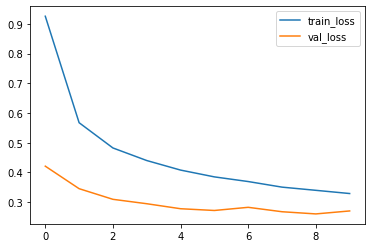

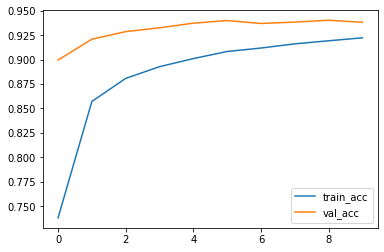

In [12]:
# 绘制loss曲线
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.legend()
plt.show()
# 绘制accuracy曲线
plt.plot(history.history['categorical_accuracy'], label='train_acc')
plt.plot(history.history['val_categorical_accuracy'], label='val_acc')
plt.legend()
plt.show()